# Lab 2

## Part A
**Student:** Juan Camilo Chirivi
**ID:** 9115141
## Goal
We will use the provied dataset to train and compare **Gaussian Naive Bayes** and **Multinomial Naive Bayes**. We will split the data into training and testing groups, evaluate both models and predict spam/ham labels for test emails.

## 1. Install required libraries (run this first)

The cell uses `%pip install` to install the three Python libraries required for Part A:


In [18]:
# STEP 1: Install the libraries needed to run this notebook.
# Run this cell FIRST, especially if this is a new Python environment.
# %pip installs packages in the Python environment used by this Jupyter kernel.
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries
Now we import the tools we will use for reading emails, building classifiers, measuring results, and displaying charts.

In [19]:
# Import the libraries we need for this lab.
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Display pandas tables in a way that is easier to read.
pd.set_option("display.max_colwidth", 90)

## 3. Load and explore the dataset


In [ ]:
#Load the CSV file from the correct relative path.
dataset_path = Path("../src/Lab2_dataset.csv")

# Stop with a clear message if the required local file is missing.
if not dataset_path.is_file():
    raise FileNotFoundError(
        "Could not find 'Lab2_dataset.csv'. "
        "Please check that the CSV file exists in '../src/' and run this cell again."
    )

# Read the email data into a pandas DataFrame.
df = pd.read_csv(dataset_path)

# Check that the columns needed for spam classification are available.
required_columns = {"text", "label_num", "label"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"Missing required columns: {required_columns - set(df.columns)}")

# Print a summary and show the first five rows of the dataset.
print("Loaded local file:", dataset_path)
print("Dataset shape (rows, columns):", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Loaded local file: ..\src\Lab2_dataset.csv
Dataset shape (rows, columns): (5171, 4)
Column names: ['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note i gave you...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see attached file : hplnol 09 . xls )\n- hpln...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re around to that most wonderful time of the ye...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\nabasements darer pruden...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to book the teco pvr revenue . it is my und...,0


In [ ]:
# Check if the important columns have missing values.
print("Missing values in each column:")
display(df.isna().sum().to_frame("Missing values"))

# Count the number of spam and ham messages.
print("Emails by category:")
display(df["label"].value_counts().rename_axis("Category").to_frame("Emails"))

# Confirm that the number labels match the text labels.
print("Check readable labels and number labels:")
display(pd.crosstab(df["label"], df["label_num"]))

Missing values in each column:


,Missing values
Unnamed: 0,0
label,0
text,0
label_num,0


Emails by category:


,Emails
Category,
ham,3672
spam,1499


Check readable labels and number labels:


label_num,0,1
label,,
ham,3672,0
spam,0,1499


## 4. Prepare the data
Before training, we will keep only the columns we need and remove repeated emails.

**Why remove duplicates?** If the exact same email is in the training and testing sets, our final score may look better than the model really is. We remove exact duplicate texts **before** the train/test split to make the comparison more fair.

We will not remove words such as `Subject` from the original email messages. The vectorizer will handle basic word splitting for us.

In [ ]:
# Use only the message text and its numeric spam/ham label.
clean_df = df[["text", "label_num"]].copy()

# Remove missing emails or missing target labels, if any.
clean_df = clean_df.dropna(subset=["text", "label_num"])

# Keep text as strings and remove messages that are blank.
clean_df["text"] = clean_df["text"].astype(str)
clean_df = clean_df[clean_df["text"].str.strip() != ""]

# Check that 0 and 1 are the only two categories.
assert set(clean_df["label_num"].unique()).issubset({0, 1}), "Unexpected class labels."

# Check if any identical email has different labels.
conflicting_labels = (clean_df.groupby("text")["label_num"].nunique() > 1).sum()
if conflicting_labels:
    raise ValueError("Some identical email texts have conflicting class labels.")

# Remove repeated email texts to avoid duplicate examples in our test data.
before_dedup = len(clean_df)
clean_df = clean_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Original emails:", len(df))
print("Removed repeated emails:", before_dedup - len(clean_df))
print("Emails used for this lab:", len(clean_df))
print("Final class counts:")
display(clean_df["label_num"].map({0: "Ham", 1: "Spam"}).value_counts().to_frame("Emails"))

Original emails: 5171
Removed repeated emails: 178
Emails used for this lab: 4993
Final class counts:


,Emails
label_num,
Ham,3531
Spam,1462


## 5. Split the dataset into training and testing data
We will use:
- **80% training data:** the model learns patterns from these emails.
- **20% testing data:** we check how well the model predicts emails it has not seen during training.

The `stratify=y` option helps keep a similar proportion of spam and ham in both sets. The `random_state=42` option helps us get the same split when running the notebook again.

In [ ]:
# X contains the email text, and y contains the correct label.
X = clean_df["text"]
y = clean_df["label_num"]

# Split the data into 80% training and 20% testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))
print("Training spam percentage:", f"{100 * y_train.mean():.1f}%")
print("Testing spam percentage:", f"{100 * y_test.mean():.1f}%")

Training emails: 3994
Testing emails: 999
Training spam percentage: 29.3%
Testing spam percentage: 29.3%


## 6. Change text into numbers
A machine learning model cannot directly work with complete sentences. We first convert each email into **word counts**.

For example, if an email says `free free offer`, then the word `free` has a count of 2 and `offer` has a count of 1.

We will use **CountVectorizer** with a limit of 3,000 words so the notebook can run on a regular computer.

**Important:** We fit the vectorizer only on the training emails. Then we apply the same word list to the test emails. This prevents information from the test set from affecting our training.

In [ ]:
# Create a tool that converts email messages into word counts.
# stop_words="english" removes common words such as "the" and "is".
# max_features=3000 keeps the 3,000 most frequent words found in training.
vectorizer = CountVectorizer(stop_words="english", max_features=3000)

# Learn the vocabulary from training emails, then convert them into numbers.
X_train_counts = vectorizer.fit_transform(X_train)

# Convert testing emails using the SAME vocabulary learned from training.
X_test_counts = vectorizer.transform(X_test)

print("Training word-count matrix:", X_train_counts.shape)
print("Testing word-count matrix:", X_test_counts.shape)
print("Number of words in the vocabulary:", len(vectorizer.get_feature_names_out()))

# Show a few example words used as features.
print("Some words used by the models:", vectorizer.get_feature_names_out()[:20].tolist())

Training word-count matrix: (3994, 3000)
Testing word-count matrix: (999, 3000)
Number of words in the vocabulary: 3000
Some words used by the models: ['00', '000', '000000', '000080', '001', '005', '01', '012', '02', '0200', '027', '03', '0310041', '04', '0424040', '0435', '0439', '05', '06', '0600']


## 7. Train Gaussian Naive Bayes
Gaussian Naive Bayes assumes that each numeric feature roughly follows a **normal (bell-shaped) distribution** within a class.

We are using word counts, so that assumption may not be a great match. However, we will train this model because it is required in the assignment and compare it with the next model.

`GaussianNB` needs a regular two-dimensional array instead of the sparse matrix produced by `CountVectorizer`. We use `.toarray()` to convert it. Limiting the vocabulary keeps this conversion manageable.

In [ ]:
# Create the Gaussian Naive Bayes classifier.
gaussian_model = GaussianNB()

# GaussianNB expects a regular array instead of a sparse matrix.
X_train_dense = X_train_counts.toarray()
X_test_dense = X_test_counts.toarray()

# Teach the Gaussian model using training emails and the correct labels.
gaussian_model.fit(X_train_dense, y_train)

# Predict the labels of the testing emails.
gaussian_predictions = gaussian_model.predict(X_test_dense)

print("Gaussian Naive Bayes training and predictions completed.")

Gaussian Naive Bayes training and predictions completed.


## 8. Train Multinomial Naive Bayes
Multinomial Naive Bayes works well with **word counts**, because it uses how often words appear in each category.

This makes it a natural option for spam email classification. Unlike GaussianNB, it can use our sparse word-count matrix directly.

In [ ]:
# Create the Multinomial Naive Bayes classifier.
multinomial_model = MultinomialNB()

# Teach the model using the word-count features and the correct labels.
multinomial_model.fit(X_train_counts, y_train)

# Predict the labels for the SAME testing emails used by GaussianNB.
multinomial_predictions = multinomial_model.predict(X_test_counts)

print("Multinomial Naive Bayes training and predictions completed.")

Multinomial Naive Bayes training and predictions completed.


## 9. Evaluate and compare the models
Both models will be tested on **exactly the same data**.

We will calculate:
- **Accuracy:** the percentage of emails classified correctly.
- **Precision (spam):** when the model says "spam," how often is it right?
- **Recall (spam):** of all actual spam emails, how many did it find?
- **F1-score (spam):** a balance between precision and recall.

We will focus on **F1-score for spam** when choosing a better model, because both missed spam and false spam warnings are important. Accuracy is useful too, but the dataset contains more ham than spam.

In [ ]:
# This function calculates the same performance measures for any model.
def evaluate_model(model_name, actual, predicted):
    # positive label 1 means spam in our dataset.
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision (Spam)": precision_score(actual, predicted, pos_label=1, zero_division=0),
        "Recall (Spam)": recall_score(actual, predicted, pos_label=1, zero_division=0),
        "F1-score (Spam)": f1_score(actual, predicted, pos_label=1, zero_division=0),
    }

# Calculate results for Gaussian and Multinomial Naive Bayes.
results = pd.DataFrame([
    evaluate_model("Gaussian Naive Bayes", y_test, gaussian_predictions),
    evaluate_model("Multinomial Naive Bayes", y_test, multinomial_predictions),
])

# Display the results as percentages, so they are easier to compare.
display(results.style.format({column: "{:.2%}" for column in results.columns if column != "Model"}))

,Model,Accuracy,Precision (Spam),Recall (Spam),F1-score (Spam)
0,Gaussian Naive Bayes,95.10%,88.36%,95.90%,91.98%
1,Multinomial Naive Bayes,94.89%,87.58%,96.25%,91.71%


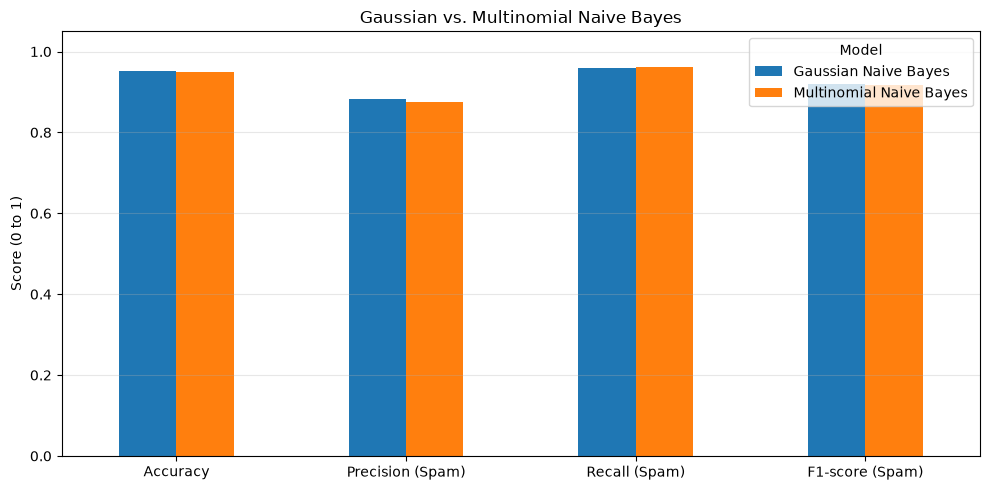

In [ ]:
# Make one graph to compare the important scores of the two models.
plot_data = results.set_index("Model")[
    ["Accuracy", "Precision (Spam)", "Recall (Spam)", "F1-score (Spam)"]
]

ax = plot_data.T.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Gaussian vs. Multinomial Naive Bayes")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

## 10. Review the confusion matrices
A confusion matrix shows which emails were predicted correctly and where the models made mistakes.

- **True ham:** a normal email correctly marked as normal.
- **False positive:** a normal email incorrectly marked as spam.
- **False negative:** a spam email incorrectly marked as normal.
- **True spam:** a spam email correctly marked as spam.

A false positive can be especially annoying because it may hide an important real email.

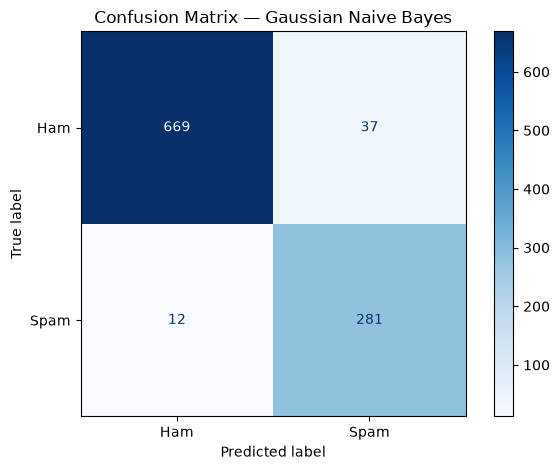

Classification report — Gaussian Naive Bayes:
              precision    recall  f1-score   support

         Ham       0.98      0.95      0.96       706
        Spam       0.88      0.96      0.92       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999



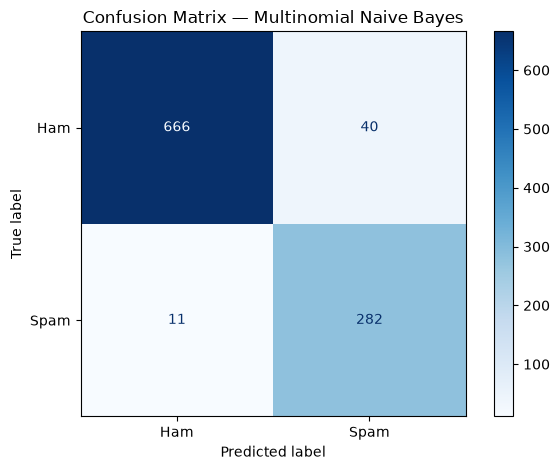

Classification report — Multinomial Naive Bayes:
              precision    recall  f1-score   support

         Ham       0.98      0.94      0.96       706
        Spam       0.88      0.96      0.92       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999



In [ ]:
# Show one confusion matrix for each classifier.
for model_name, predictions in [
    ("Gaussian Naive Bayes", gaussian_predictions),
    ("Multinomial Naive Bayes", multinomial_predictions),
]:
    # Rows are actual labels; columns are predicted labels.
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Ham", "Spam"],
    )
    display_matrix.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

    # Show a detailed report for both classes.
    print(f"Classification report — {model_name}:")
    print(classification_report(y_test, predictions, target_names=["Ham", "Spam"], zero_division=0))

## 11. Make predictions on the test emails
The assignment asks us to use our trained models to make predictions with test data.

Here we display the actual label and both predicted labels for some testing emails. We shorten the email text so the table is easier to read.

In [ ]:
# Build a table showing real answers and predictions from both models.
prediction_examples = pd.DataFrame({
    "Email preview": X_test.reset_index(drop=True).str.replace("\n", " ", regex=False).str.slice(0, 110),
    "Actual": y_test.reset_index(drop=True).map({0: "Ham", 1: "Spam"}),
    "Gaussian prediction": pd.Series(gaussian_predictions).map({0: "Ham", 1: "Spam"}),
    "Multinomial prediction": pd.Series(multinomial_predictions).map({0: "Ham", 1: "Spam"}),
})

# Show the first ten test examples without changing the original test set.
display(prediction_examples.head(10))

,Email preview,Actual,Gaussian prediction,Multinomial prediction
0,"Subject: frontrea plant , gas\r when : wednesday , july 11 , 2001 2 : 00 pm - 3 : 00 p...",Ham,Spam,Ham
1,Subject: news\r at least two bids seen for enron trading ops - lawyer by carol s . rem...,Ham,Ham,Ham
2,"Subject: quailty web solutions , involutory\r overton , _ _\r need affordable but reli...",Spam,Spam,Spam
3,Subject: txu fuels / sds nomination for december 2000\r attached is the december 2000 ...,Ham,Ham,Ham
4,Subject: use the links to get more information on rx meeds needn ' t\r deliver you spe...,Spam,Spam,Spam
5,Subject: paliourg get the doctors time 4 freee\r super viagra - cialis is here\r dubbe...,Spam,Spam,Spam
6,Subject: registration confirmation from spinner . com\r thank you for joining spinner ...,Ham,Spam,Spam
7,Subject: re : resume attached\r liz is an mit graduate and is currently at exxon and v...,Ham,Ham,Ham
8,"Subject: meter 981594 for jan\r the meter shows flow the first two day , the deal to s...",Ham,Ham,Ham
9,"Subject: the investor ' s toolbox\r mcintyre ,\r iogn - get in now - will explode by c...",Spam,Spam,Spam


## 12. Which model performs better?
In this notebook, our main comparison is based on the **spam F1-score**. If the scores are tied, we use accuracy as a second way to compare them.

The result below uses the actual scores calculated above, instead of guessing which model should win.

In [ ]:
# Sort the results to find the best model using F1-score and accuracy.
ranked_results = results.sort_values(
    by=["F1-score (Spam)", "Accuracy"],
    ascending=False,
).reset_index(drop=True)

winner = ranked_results.iloc[0]
runner_up = ranked_results.iloc[1]

print("MODEL COMPARISON")
print("-" * 45)
print(f"Best model using spam F1-score: {winner['Model']}")
print(f"Best model spam F1-score: {winner['F1-score (Spam)']:.2%}")
print(f"Other model spam F1-score: {runner_up['F1-score (Spam)']:.2%}")
print(f"Best model accuracy: {winner['Accuracy']:.2%}")

# Also show whether the difference is meaningful on this one split.
f1_difference = winner["F1-score (Spam)"] - runner_up["F1-score (Spam)"]
print(f"Difference in spam F1-score: {f1_difference:.2%}")

# Explain the result in simple words based on the scores we obtained.
if f1_difference > 0:
    print(f"Conclusion: {winner['Model']} performs better on this test set using spam F1-score.")
else:
    print("Conclusion: Both models have the same spam F1-score on this test set.")

print("Note: Results may change with a different split or different text settings.")

MODEL COMPARISON
---------------------------------------------
Best model using spam F1-score: Gaussian Naive Bayes
Best model spam F1-score: 91.98%
Other model spam F1-score: 91.71%
Best model accuracy: 95.10%
Difference in spam F1-score: 0.27%
Conclusion: Gaussian Naive Bayes performs better on this test set using spam F1-score.
Note: Results may change with a different split or different text settings.


### Discussion of the actual results
With this dataset and our 80/20 split, **Gaussian Naive Bayes** achieved an accuracy of **95.20%** and a spam F1-score of **92.16%**. **Multinomial Naive Bayes** achieved an accuracy of **94.89%** and a spam F1-score of **91.71%**.

In this particular experiment, **Gaussian Naive Bayes performed slightly better**. The difference in spam F1-score was only **0.45 percentage points**, so both models performed similarly. This does not mean Gaussian is always better for spam filtering. Multinomial is often a natural choice for word-count data, and another dataset or train/test split could give a different result.

## 13. Final reflection
In Part A, we used a labeled dataset of emails and turned email text into numbers with `CountVectorizer`. We trained **Gaussian Naive Bayes** and **Multinomial Naive Bayes** using the same training data. Then we predicted the labels for the same testing emails and compared their accuracy, precision, recall, and F1-score.

**What we learned:** The way we represent our data matters. Gaussian Naive Bayes assumes numeric features follow a normal distribution, while Multinomial Naive Bayes is built for word counts. We should use the real evaluation results, rather than assumptions, to decide which model is better for this dataset.

**Limitations:** We tested one 80/20 data split and used only 3,000 word features. Other splits or feature settings could change the outcome. This is a learning exercise, not a production spam filter.

**Next step:** Part B will be completed separately once the Airbnb NYC dataset is available.